

# US-firearm-background-checks-analysis

## Table of Contents
<ul>
<li><a href="#intro">Introduction</a></li>
<li><a href="#wrangling">Data Wrangling</a></li>
<li><a href="#eda">Exploratory Data Analysis</a></li>
<li><a href="#conclusions">Conclusions</a></li>
</ul>

<a id='intro'></a>
## Introduction

### Dataset Description 

This project examines two datasets:
- FBI NICS background checks (gun_data.csv): Monthly background-check records by state or territory. Relevant fields include month, state, and totals, along with transaction categories such as handgun, long_gun, and permit.
- U.S. Census (US_Census_Data.csv): State-level demographic and socioeconomic indicators. Fact identifies each indicator, Fact Note provides annotations, and the state columns contain indicator values.

The datasets are compared by state name. The analysis uses full calendar years for the historical trend and compares 2016 NICS totals with selected Census measures for cross-state analysis. The population estimate is for July 2016; the income indicator is median household income in 2015 dollars for 2011–2015, so the socioeconomic measures do not all describe the exact same period. NICS checks are transactions, not firearm sales or individual gun owners.

### Question(s) for Analysis
>***1.*** How did total NICS background checks change in the United States between 1999 and 2016?

>***2.*** Do states with larger populations necessarily have higher NICS background check rates per 1,000 residents?

>***3.*** Is median household income associated with NICS background check rates across states?

>***4.*** How are state poverty rates associated with NICS background check rates?

The 2016 state comparisons use checks per 1,000 residents as the outcome, with population size, income, and poverty as explanatory variables. These are descriptive associations, not causal tests.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

<a id='wrangling'></a>
## Data Wrangling
### General Properties — Load and inspect both datasets

First, inspect the dataset structure, coverage, missing values, and duplicates.

In [2]:
# Load monthly NICS background check records. 
df_gun = pd.read_csv("Database_Ncis_and_Census_data/gun_data.csv")
df_gun.head()

,month,state,permit,permit_recheck,handgun,long_gun,other,multiple,admin,prepawn_handgun,...,returned_other,rentals_handgun,rentals_long_gun,private_sale_handgun,private_sale_long_gun,private_sale_other,return_to_seller_handgun,return_to_seller_long_gun,return_to_seller_other,totals
0,2017-09,Alabama,16717.0,0.0,5734.0,6320.0,221.0,317,0.0,15.0,...,0.0,0.0,0.0,9.0,16.0,3.0,0.0,0.0,3.0,32019
1,2017-09,Alaska,209.0,2.0,2320.0,2930.0,219.0,160,0.0,5.0,...,0.0,0.0,0.0,17.0,24.0,1.0,0.0,0.0,0.0,6303
2,2017-09,Arizona,5069.0,382.0,11063.0,7946.0,920.0,631,0.0,13.0,...,0.0,0.0,0.0,38.0,12.0,2.0,0.0,0.0,0.0,28394
3,2017-09,Arkansas,2935.0,632.0,4347.0,6063.0,165.0,366,51.0,12.0,...,0.0,0.0,0.0,13.0,23.0,0.0,0.0,2.0,1.0,17747
4,2017-09,California,57839.0,0.0,37165.0,24581.0,2984.0,0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,123506


In [3]:
df_gun.describe()

,permit,permit_recheck,handgun,long_gun,other,multiple,admin,prepawn_handgun,prepawn_long_gun,prepawn_other,...,returned_other,rentals_handgun,rentals_long_gun,private_sale_handgun,private_sale_long_gun,private_sale_other,return_to_seller_handgun,return_to_seller_long_gun,return_to_seller_other,totals
count,12461.000000,1100.000000,12465.000000,12466.000000,5500.000000,12485.000000,12462.000000,10542.000000,10540.000000,5115.000000,...,1815.000000,990.000000,825.000000,2750.000000,2750.000000,2750.000000,2475.000000,2750.000000,2255.000000,12485.000000
mean,6413.629404,1165.956364,5940.881107,7810.847585,360.471636,268.603364,58.898090,4.828021,7.834156,0.165591,...,1.027548,0.076768,0.087273,14.936000,11.602909,1.030182,0.402020,0.441818,0.105987,21595.725911
std,23752.338269,9224.200609,8618.584060,9309.846140,1349.478273,783.185073,604.814818,10.907756,16.468028,1.057105,...,4.386296,0.634503,0.671649,71.216021,54.253090,4.467843,1.446568,1.528223,0.427363,32591.418387
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,865.000000,2078.250000,17.000000,15.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4638.000000
50%,518.000000,0.000000,3059.000000,5122.000000,121.000000,125.000000,0.000000,0.000000,1.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,12399.000000
75%,4272.000000,0.000000,7280.000000,10380.750000,354.000000,301.000000,0.000000,5.000000,8.000000,0.000000,...,0.000000,0.000000,0.000000,2.000000,4.000000,0.000000,0.000000,0.000000,0.000000,25453.000000
max,522188.000000,116681.000000,107224.000000,108058.000000,77929.000000,38907.000000,28083.000000,164.000000,269.000000,49.000000,...,64.000000,12.000000,12.000000,1017.000000,777.000000,71.000000,28.000000,17.000000,4.000000,541978.000000


In [4]:
#Load NCIS database
df_census = pd.read_csv("Database_Ncis_and_Census_data/US_Census_Data.csv")
df_census.head()

,Fact,Fact Note,Alabama,Alaska,Arizona,Arkansas,California,Colorado,Connecticut,Delaware,...,South Dakota,Tennessee,Texas,Utah,Vermont,Virginia,Washington,West Virginia,Wisconsin,Wyoming
0,"Population estimates, July 1, 2016, (V2016)",NaN,"4,863,300","741,894","6,931,071","2,988,248","39,250,017","5,540,545","3,576,452","952,065",...,865454,6651194,"27,862,596","3,051,217","624,594","8,411,808","7,288,000","1,831,102","5,778,708","585,501"
1,"Population estimates base, April 1, 2010, (V2...",NaN,"4,780,131","710,249","6,392,301","2,916,025","37,254,522","5,029,324","3,574,114","897,936",...,814195,6346298,"25,146,100","2,763,888","625,741","8,001,041","6,724,545","1,853,011","5,687,289","563,767"
2,"Population, percent change - April 1, 2010 (es...",NaN,1.70%,4.50%,8.40%,2.50%,5.40%,10.20%,0.10%,6.00%,...,0.063,0.048,10.80%,10.40%,-0.20%,5.10%,8.40%,-1.20%,1.60%,3.90%
3,"Population, Census, April 1, 2010",NaN,"4,779,736","710,231","6,392,017","2,915,918","37,253,956","5,029,196","3,574,097","897,934",...,814180,6346105,"25,145,561","2,763,885","625,741","8,001,024","6,724,540","1,852,994","5,686,986","563,626"
4,"Persons under 5 years, percent, July 1, 2016, ...",NaN,6.00%,7.30%,6.30%,6.40%,6.30%,6.10%,5.20%,5.80%,...,0.071,0.061,7.20%,8.30%,4.90%,6.10%,6.20%,5.50%,5.80%,6.50%


In [5]:
df_gun.shape, df_census.shape

((12485, 27), (85, 52))

In [6]:
df_gun.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12485 entries, 0 to 12484
Data columns (total 27 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   month                      12485 non-null  object 
 1   state                      12485 non-null  object 
 2   permit                     12461 non-null  float64
 3   permit_recheck             1100 non-null   float64
 4   handgun                    12465 non-null  float64
 5   long_gun                   12466 non-null  float64
 6   other                      5500 non-null   float64
 7   multiple                   12485 non-null  int64  
 8   admin                      12462 non-null  float64
 9   prepawn_handgun            10542 non-null  float64
 10  prepawn_long_gun           10540 non-null  float64
 11  prepawn_other              5115 non-null   float64
 12  redemption_handgun         10545 non-null  float64
 13  redemption_long_gun        10544 non-null  flo

In [7]:
df_census.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 85 entries, 0 to 84
Data columns (total 52 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Fact            80 non-null     object
 1   Fact Note       28 non-null     object
 2   Alabama         65 non-null     object
 3   Alaska          65 non-null     object
 4   Arizona         65 non-null     object
 5   Arkansas        65 non-null     object
 6   California      65 non-null     object
 7   Colorado        65 non-null     object
 8   Connecticut     65 non-null     object
 9   Delaware        65 non-null     object
 10  Florida         65 non-null     object
 11  Georgia         65 non-null     object
 12  Hawaii          65 non-null     object
 13  Idaho           65 non-null     object
 14  Illinois        65 non-null     object
 15  Indiana         65 non-null     object
 16  Iowa            65 non-null     object
 17  Kansas          65 non-null     object
 18  Kentucky    

### General Properties- Gun Data
 Inspect missing values and duplicates before deciding which fields need cleaning.

In [8]:
df_gun.isna().sum()

month                            0
state                            0
permit                          24
permit_recheck               11385
handgun                         20
long_gun                        19
other                         6985
multiple                         0
admin                           23
prepawn_handgun               1943
prepawn_long_gun              1945
prepawn_other                 7370
redemption_handgun            1940
redemption_long_gun           1941
redemption_other              7370
returned_handgun             10285
returned_long_gun            10340
returned_other               10670
rentals_handgun              11495
rentals_long_gun             11660
private_sale_handgun          9735
private_sale_long_gun         9735
private_sale_other            9735
return_to_seller_handgun     10010
return_to_seller_long_gun     9735
return_to_seller_other       10230
totals                           0
dtype: int64

In [9]:
df_gun.duplicated().sum()

0

In [10]:
df_gun["state"].unique()

array(['Alabama', 'Alaska', 'Arizona', 'Arkansas', 'California',
       'Colorado', 'Connecticut', 'Delaware', 'District of Columbia',
       'Florida', 'Georgia', 'Guam', 'Hawaii', 'Idaho', 'Illinois',
       'Indiana', 'Iowa', 'Kansas', 'Kentucky', 'Louisiana', 'Maine',
       'Mariana Islands', 'Maryland', 'Massachusetts', 'Michigan',
       'Minnesota', 'Mississippi', 'Missouri', 'Montana', 'Nebraska',
       'Nevada', 'New Hampshire', 'New Jersey', 'New Mexico', 'New York',
       'North Carolina', 'North Dakota', 'Ohio', 'Oklahoma', 'Oregon',
       'Pennsylvania', 'Puerto Rico', 'Rhode Island', 'South Carolina',
       'South Dakota', 'Tennessee', 'Texas', 'Utah', 'Vermont',
       'Virgin Islands', 'Virginia', 'Washington', 'West Virginia',
       'Wisconsin', 'Wyoming'], dtype=object)

***Initial observations***: There are no fully duplicated gun-data rows. month, state, and totals have no missing values. Several transaction-category fields contain missing values, but they are not needed for the annual totals trend. No imputation is applied to those fields at this stage.

### General Properties - Geographic Coverage
Gun data includes areas beyond 50 states in the census table. identify the nonmatching names before selecting a common geographic scope.

In [11]:
df_gun[~df_gun["state"].isin(df_census.columns)]["state"].unique()

array(['District of Columbia', 'Guam', 'Mariana Islands', 'Puerto Rico',
       'Virgin Islands'], dtype=object)

Five gun-data areas are absent from the census state columns: District of Columbia, Guam, Mariana Islands, Puerto Rico, Virgin Islands. A separate 50-state subset is useful for future combined analyses. The original gun dataset is preserved for the nationwide historical trend.

### General Properties — Census Data
The Census table has 85 rows and 52 columns: Fact, Fact Note, and 50 state columns. We still need to inspect indicator rows, value formats, notes, and reference years before selecting variables or cleaning them.

In [12]:
df_census[["Fact","Fact Note"]].head(15)

,Fact,Fact Note
0,"Population estimates, July 1, 2016, (V2016)",NaN
1,"Population estimates base, April 1, 2010, (V2...",NaN
2,"Population, percent change - April 1, 2010 (es...",NaN
3,"Population, Census, April 1, 2010",NaN
4,"Persons under 5 years, percent, July 1, 2016, ...",NaN
5,"Persons under 5 years, percent, April 1, 2010",NaN
6,"Persons under 18 years, percent, July 1, 2016,...",NaN
7,"Persons under 18 years, percent, April 1, 2010",NaN
8,"Persons 65 years and over, percent, July 1, 2...",NaN
9,"Persons 65 years and over, percent, April 1, 2010",NaN


### Data Cleaning- Prepare analysis variables
 Convert the monthly date field to datetime, extract the year, and create a separate subset for comparisons with Census. Avoid deleting the original records.

In [13]:
df_gun["month"].tail()

12480    1998-11
12481    1998-11
12482    1998-11
12483    1998-11
12484    1998-11
Name: month, dtype: object

In [14]:
df_gun["month"] = pd.to_datetime(df_gun["month"], format="%Y-%m")
df_gun["year"]=df_gun["month"].dt.year 

In [15]:
df_gun["year"].unique()

array([2017, 2016, 2015, 2014, 2013, 2012, 2011, 2010, 2009, 2008, 2007,
       2006, 2005, 2004, 2003, 2002, 2001, 2000, 1999, 1998])

In [16]:
df_gun.groupby("year")["month"].nunique()

year
1998     2
1999    12
2000    12
2001    12
2002    12
2003    12
2004    12
2005    12
2006    12
2007    12
2008    12
2009    12
2010    12
2011    12
2012    12
2013    12
2014    12
2015    12
2016    12
2017     9
Name: month, dtype: int64

***Date coverage***: The data begins in November 1998 and ends in September 2017. The years 1999–2016 each have 12 months, so those years are used for full-year comparisons. The partial boundary years are not used in the annual trend.

In [17]:
gun_states = df_gun[df_gun["state"].isin(df_census.columns)].copy()
gun_states["state"].nunique()

50

**Geographic cleaning decision**: gun_states contains only states shared by both datasets. This is a separate working copy for future Census comparisons; it does not replace df_gun in RQ1.

### Data Cleaning — Select and standardize Census indicators
The Census file includes indicator rows and notes. Select the population, median household income, and poverty indicators; normalize mixed numeric formats before joining with 2016 NICS totals.

A reusable extract_census_data() function extracts each indicator and converts numeric values. For poverty, it also normalizes decimal fractions and percent strings into percentage points.

In [18]:
df_census.tail(25)

,Fact,Fact Note,Alabama,Alaska,Arizona,Arkansas,California,Colorado,Connecticut,Delaware,...,South Dakota,Tennessee,Texas,Utah,Vermont,Virginia,Washington,West Virginia,Wisconsin,Wyoming
60,"Veteran-owned firms, 2012",NaN,"41,943","7,953","46,780","25,915","252,377","51,722","31,056","7,206",...,8604,59379,"213,590","18,754","8,237","76,434","49,331","12,912","39,830","6,470"
61,"Nonveteran-owned firms, 2012",NaN,"316,984","56,091","427,582","192,988","3,176,341","469,524","281,182","60,318",...,66219,469392,"2,057,218","219,807","63,317","548,439","461,401","94,960","370,755","51,353"
62,"Population per square mile, 2010",NaN,94.4,1.2,56.3,56,239.1,48.5,738.1,460.8,...,10.7,153.9,96.3,33.6,67.9,202.6,101.2,77.1,105,5.8
63,"Land area in square miles, 2010",NaN,"50,645.33","570,640.95","113,594.08","52,035.48","155,779.22","103,641.89","4,842.36","1,948.54",...,75811,41234.9,"261,231.71","82,169.62","9,216.66","39,490.09","66,455.52","24,038.21","54,157.80","97,093.14"
64,FIPS Code,NaN,"""01""","""02""","""04""","""05""","""06""","""08""","""09""","""10""",...,"""46""","""47""","""48""","""49""","""50""","""51""","""53""","""54""","""55""","""56"""
65,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
66,NOTE: FIPS Code values are enclosed in quotes ...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
67,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
68,Value Notes,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
69,1,Includes data not distributed by county.,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [19]:
df_census["Fact"].tolist()

['Population estimates, July 1, 2016,  (V2016)',
 'Population estimates base, April 1, 2010,  (V2016)',
 'Population, percent change - April 1, 2010 (estimates base) to July 1, 2016,  (V2016)',
 'Population, Census, April 1, 2010',
 'Persons under 5 years, percent, July 1, 2016,  (V2016)',
 'Persons under 5 years, percent, April 1, 2010',
 'Persons under 18 years, percent, July 1, 2016,  (V2016)',
 'Persons under 18 years, percent, April 1, 2010',
 'Persons 65 years and over, percent,  July 1, 2016,  (V2016)',
 'Persons 65 years and over, percent, April 1, 2010',
 'Female persons, percent,  July 1, 2016,  (V2016)',
 'Female persons, percent, April 1, 2010',
 'White alone, percent, July 1, 2016,  (V2016)',
 'Black or African American alone, percent, July 1, 2016,  (V2016)',
 'American Indian and Alaska Native alone, percent, July 1, 2016,  (V2016)',
 'Asian alone, percent, July 1, 2016,  (V2016)',
 'Native Hawaiian and Other Pacific Islander alone, percent, July 1, 2016,  (V2016)',
 'Tw

In [20]:
census_clean = df_census.iloc[:65].copy()
census_clean 

,Fact,Fact Note,Alabama,Alaska,Arizona,Arkansas,California,Colorado,Connecticut,Delaware,...,South Dakota,Tennessee,Texas,Utah,Vermont,Virginia,Washington,West Virginia,Wisconsin,Wyoming
0,"Population estimates, July 1, 2016, (V2016)",NaN,"4,863,300","741,894","6,931,071","2,988,248","39,250,017","5,540,545","3,576,452","952,065",...,865454,6651194,"27,862,596","3,051,217","624,594","8,411,808","7,288,000","1,831,102","5,778,708","585,501"
1,"Population estimates base, April 1, 2010, (V2...",NaN,"4,780,131","710,249","6,392,301","2,916,025","37,254,522","5,029,324","3,574,114","897,936",...,814195,6346298,"25,146,100","2,763,888","625,741","8,001,041","6,724,545","1,853,011","5,687,289","563,767"
2,"Population, percent change - April 1, 2010 (es...",NaN,1.70%,4.50%,8.40%,2.50%,5.40%,10.20%,0.10%,6.00%,...,0.063,0.048,10.80%,10.40%,-0.20%,5.10%,8.40%,-1.20%,1.60%,3.90%
3,"Population, Census, April 1, 2010",NaN,"4,779,736","710,231","6,392,017","2,915,918","37,253,956","5,029,196","3,574,097","897,934",...,814180,6346105,"25,145,561","2,763,885","625,741","8,001,024","6,724,540","1,852,994","5,686,986","563,626"
4,"Persons under 5 years, percent, July 1, 2016, ...",NaN,6.00%,7.30%,6.30%,6.40%,6.30%,6.10%,5.20%,5.80%,...,0.071,0.061,7.20%,8.30%,4.90%,6.10%,6.20%,5.50%,5.80%,6.50%
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
60,"Veteran-owned firms, 2012",NaN,"41,943","7,953","46,780","25,915","252,377","51,722","31,056","7,206",...,8604,59379,"213,590","18,754","8,237","76,434","49,331","12,912","39,830","6,470"
61,"Nonveteran-owned firms, 2012",NaN,"316,984","56,091","427,582","192,988","3,176,341","469,524","281,182","60,318",...,66219,469392,"2,057,218","219,807","63,317","548,439","461,401","94,960","370,755","51,353"
62,"Population per square mile, 2010",NaN,94.4,1.2,56.3,56,239.1,48.5,738.1,460.8,...,10.7,153.9,96.3,33.6,67.9,202.6,101.2,77.1,105,5.8
63,"Land area in square miles, 2010",NaN,"50,645.33","570,640.95","113,594.08","52,035.48","155,779.22","103,641.89","4,842.36","1,948.54",...,75811,41234.9,"261,231.71","82,169.62","9,216.66","39,490.09","66,455.52","24,038.21","54,157.80","97,093.14"


In [21]:
census_clean.iloc[:, 2:].isna().sum()

Alabama           0
Alaska            0
Arizona           0
Arkansas          0
California        0
Colorado          0
Connecticut       0
Delaware          0
Florida           0
Georgia           0
Hawaii            0
Idaho             0
Illinois          0
Indiana           0
Iowa              0
Kansas            0
Kentucky          0
Louisiana         0
Maine             0
Maryland          0
Massachusetts     0
Michigan          0
Minnesota         0
Mississippi       0
Missouri          0
Montana           0
Nebraska          0
Nevada            0
New Hampshire     0
New Jersey        0
New Mexico        0
New York          0
North Carolina    0
North Dakota      0
Ohio              0
Oklahoma          0
Oregon            0
Pennsylvania      0
Rhode Island      0
South Carolina    0
South Dakota      0
Tennessee         0
Texas             0
Utah              0
Vermont           0
Virginia          0
Washington        0
West Virginia     0
Wisconsin         0
Wyoming           0


In [22]:
census_clean.dtypes.value_counts()

object    52
dtype: int64

In [23]:
# Reusable extraction for numeric Census indicators.
# Poverty values may be stored as percentages ("17.1%") or fractions (0.171).
def extract_census_data(df, fact_name, dtype=float, percentage=False):
    matches = df.loc[
        df["Fact"].str.contains(fact_name, na=False, regex=False)
    ]
    if len(matches) != 1:
        raise ValueError(f"Expected one Census row for {fact_name!r}, found {len(matches)}")

    row = matches.iloc[0, 2:]

    def convert_value(value):
        text = str(value).strip()
        has_percent_sign = text.endswith("%")
        number = float(text.replace(",", "").replace("$", "").replace("%", ""))
        if percentage and not has_percent_sign and 0 <= number < 1:
            number *= 100
        return dtype(number)

    return row.apply(convert_value)



In [24]:
# Median household income (in 2015 dollars), 2011–2015.
income = extract_census_data(census_clean, "Median household income")
income.head()

Alabama       43623.0
Alaska        72515.0
Arizona       50255.0
Arkansas      41371.0
California    61818.0
Name: 47, dtype: float64

In [25]:
# Population estimates, July 1, 2016 (V2016).
population = extract_census_data(
    census_clean, "Population estimates, July 1, 2016", dtype=int
)
population.head()

Alabama        4863300
Alaska          741894
Arizona        6931071
Arkansas       2988248
California    39250017
Name: 0, dtype: int64

In [26]:
# Poverty rates are expressed in percentage points (e.g., 17.1, not 0.171).
# The source mixes percentage strings and decimal fractions, so normalize both.
poverty = extract_census_data(
    census_clean, "Persons in poverty, percent", percentage=True
)
poverty.head()

Alabama       17.1
Alaska         9.9
Arizona       16.4
Arkansas      17.2
California    14.3
Name: 49, dtype: float64

In [27]:
census_clean.loc[
    census_clean["Fact"].str.contains("Persons in poverty", na=False)
].T

,49
Fact,"Persons in poverty, percent"
Fact Note,NaN
Alabama,17.10%
Alaska,9.90%
Arizona,16.40%
Arkansas,17.20%
California,14.30%
Colorado,11.00%
Connecticut,9.80%
Delaware,11.70%


### Data Cleaning — Combine Census indicators and 2016 NICS checks
Aggregate monthly NICS totals by state for 2016, join to the 50-state Census indicators, and calculate checks per 1,000 residents.

In [28]:
census_final = pd.DataFrame({
    "Population": population,
    "Poverty": poverty,
    "Income": income
})
census_final.head()

,Population,Poverty,Income
Alabama,4863300,17.1,43623.0
Alaska,741894,9.9,72515.0
Arizona,6931071,16.4,50255.0
Arkansas,2988248,17.2,41371.0
California,39250017,14.3,61818.0


In [29]:
gun_2016=gun_states[gun_states['year']==2016].groupby("state")["totals"].sum()
gun_2016.shape

(50,)

In [30]:
final_df = census_final.join(gun_2016.rename("NICS_Checks"))
final_df.head()

,Population,Poverty,Income,NICS_Checks
Alabama,4863300,17.1,43623.0,616947
Alaska,741894,9.9,72515.0,87647
Arizona,6931071,16.4,50255.0,416279
Arkansas,2988248,17.2,41371.0,266014
California,39250017,14.3,61818.0,2377167


In [31]:
final_df["Checks_per_1000"] = (
    final_df["NICS_Checks"] / final_df["Population"]
) * 1000

final_df.head()

,Population,Poverty,Income,NICS_Checks,Checks_per_1000
Alabama,4863300,17.1,43623.0,616947,126.857689
Alaska,741894,9.9,72515.0,87647,118.139519
Arizona,6931071,16.4,50255.0,416279,60.059838
Arkansas,2988248,17.2,41371.0,266014,89.020055
California,39250017,14.3,61818.0,2377167,60.564738


In [32]:
# Confirm the merged dataset contains exactly one complete record per state.
print("Number of states:", len(final_df))
print("Missing values by column:")
print(final_df.isna().sum())
print("Duplicate state names:", final_df.index.duplicated().sum())

Number of states: 50
Missing values by column:
Population         0
Poverty            0
Income             0
NICS_Checks        0
Checks_per_1000    0
dtype: int64
Duplicate state names: 0


### Data Cleaning Summary
- Converted NICS month to datetime and extracted year. The annual trend uses 1999–2016 because 1998 and 2017 have incomplete calendar-year coverage.
- Retained the 50 states shared by both datasets for the cross-sectional comparisons; other NICS jurisdictions were not included in that comparison.
- Selected Census population, median household income, and poverty indicators and converted their values to numeric types. Poverty values required consistent percentage-point representation.
- Aggregated monthly 2016 NICS totals by state, joined them to the Census indicators, and calculated NICS checks per 1,000 residents.
- Checked the resulting dataset for missing values and duplicate state names. NICS totals are transaction counts, not gun sales.

<a id='eda'></a>
## Exploratory Data Analysis

### Reusable Analysis Functions
The following functions standardize scatter-plot labels and Pearson correlation calculations across the three state-level comparisons. Both are reused throughout the analysis.

In [33]:
def plot_relationship(df, x, y, title, xlabel):
    """
      Plot a labeled scatter 
      chart of NICS check rates
      against a state indicator.
    """
    
    ax = df.plot.scatter(x=x, y=y, figsize=(9, 5), title=title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("NICS Checks per 1,000 Residents")
    plt.show()


def calculate_correlation(df, x, y="Checks_per_1000"):
    """
    Return Pearson's r between an indicator
    and the per-capita check rate.
    """
    return df[x].corr(df[y])

### Univariate Analysis: Distribution of NICS Check Rates (2016)
First, examine the distribution of the dependent variable across the 50 states before comparing it with population, income, and poverty.

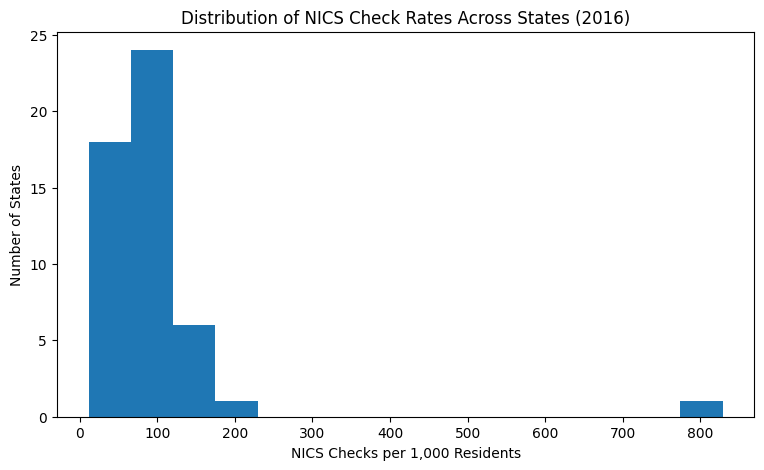

In [34]:
# One-dimensional view of state check rates; the extreme upper tail includes Kentucky.
ax = final_df["Checks_per_1000"].plot(
    kind="hist", bins=15, figsize=(9, 5),
    title="Distribution of NICS Check Rates Across States (2016)"
)
ax.set_xlabel("NICS Checks per 1,000 Residents")
ax.set_ylabel("Number of States")
plt.show()

In [35]:
# Descriptive summaries of the outcome and three explanatory variables.
final_df[["Population", "Income", "Poverty", "Checks_per_1000"]].describe()

,Population,Income,Poverty,Checks_per_1000
count,5.000000e+01,50.000000,50.000000,50.000000
mean,6.448927e+06,54311.860000,13.518000,97.695094
std,7.271769e+06,8949.529115,3.019778,111.927836
min,5.855010e+05,39665.000000,7.300000,11.676818
25%,1.850106e+06,47526.000000,11.300000,60.871917
50%,4.559320e+06,52601.000000,13.300000,83.752972
75%,7.198768e+06,60599.000000,15.375000,102.325635
max,3.925002e+07,74551.000000,20.800000,828.683468


>***Univariate finding:*** Most states have substantially lower NICS check rates than Kentucky. The unusually high Kentucky value extends the right tail of the distribution. The descriptive statistics summarize the scale and variability of each indicator; the later sensitivity analyses show whether Kentucky changes the observed relationships.

### Research Question 1: How did NICS background checks change from 1999 to 2016?

In [36]:
yearly_check= df_gun.groupby("year")["totals"].sum()
yearly_check


year
1998      891898
1999     9043747
2000     8427096
2001     8820045
2002     8367069
2003     8402244
2004     8579891
2005     8867055
2006     9993057
2007    11162272
2008    12692985
2009    13984953
2010    14320489
2011    16336732
2012    19463832
2013    20966704
2014    20860241
2015    23026288
2016    27425512
2017    17990528
Name: totals, dtype: int64

In [37]:
annual_checks = yearly_check.loc[1999:2016]
annual_changes = annual_checks.diff()
annual_changes 

year
1999          NaN
2000    -616651.0
2001     392949.0
2002    -452976.0
2003      35175.0
2004     177647.0
2005     287164.0
2006    1126002.0
2007    1169215.0
2008    1530713.0
2009    1291968.0
2010     335536.0
2011    2016243.0
2012    3127100.0
2013    1502872.0
2014    -106463.0
2015    2166047.0
2016    4399224.0
Name: totals, dtype: float64

In [38]:
annual_changes[annual_changes < 0]

year
2000   -616651.0
2002   -452976.0
2014   -106463.0
Name: totals, dtype: float64

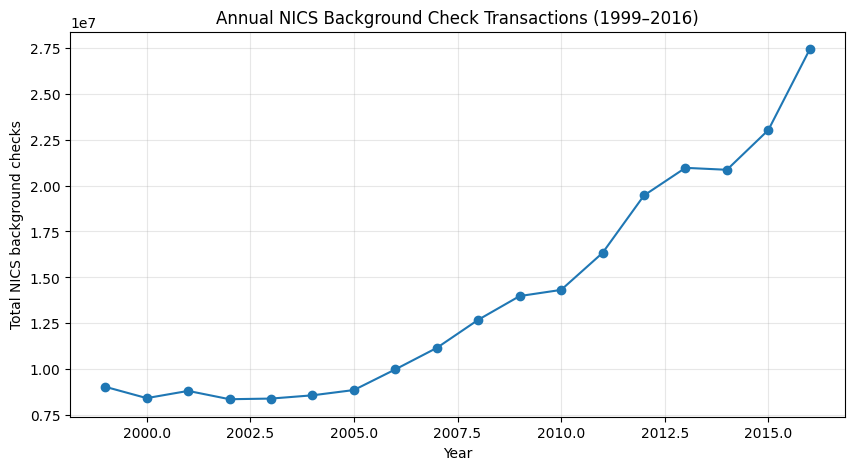

In [39]:
annual_checks.plot(
    kind="line", marker="o", figsize=(10, 5),
    title="Annual NICS Background Check Transactions (1999–2016)"
)
plt.xlabel("Year")
plt.ylabel("Total NICS background checks")
plt.grid(alpha=0.3)
plt.show()

>***Finding***: Annual NICS background check transactions increased from 9,043,747 in 1999 to 27,425,512 in 2016, an increase of approximately 203%. However, the increase was not continuous: annual totals declined in 2000, 2002, and 2014. The line plot therefore indicates a strong overall upward trend in background-check activity over the complete calendar years 1999–2016. These counts reflect transactions, not firearm sales.

In [40]:
final_df.nlargest(5, "Checks_per_1000")[
    ["Population", "NICS_Checks", "Checks_per_1000"]
]

,Population,NICS_Checks,Checks_per_1000
Kentucky,4436974,3676847,828.683468
Indiana,6633053,1436725,216.600862
Illinois,12801539,1924070,150.299898
West Virginia,1831102,242350,132.351993
Montana,1042520,136337,130.776388


In [41]:
gun_states[
    (gun_states["state"] == "Kentucky") &
    (gun_states["year"] == 2016)
][["month", "permit", "permit_recheck", "handgun", "long_gun", "totals"]]

,month,permit,permit_recheck,handgun,long_gun,totals
513,2016-12-01,358510.0,0.0,17311.0,16766.0,397059
568,2016-11-01,297507.0,0.0,12847.0,14844.0,330444
623,2016-10-01,354387.0,0.0,10111.0,10030.0,378973
678,2016-09-01,276744.0,0.0,8917.0,8172.0,298753
733,2016-08-01,9579.0,0.0,8842.0,7187.0,29746
788,2016-07-01,342858.0,0.0,9378.0,6615.0,363085
843,2016-06-01,340735.0,0.0,8703.0,6584.0,360293
898,2016-05-01,305018.0,0.0,8049.0,5244.0,321666
953,2016-04-01,285372.0,0.0,9657.0,7070.0,306214
1008,2016-03-01,294755.0,0.0,13816.0,8391.0,321318


>***Kentucky outlier explanation***: Kentucky’s 2016 total (3,676,847 checks, approximately 829 per 1,000 residents) is driven mainly by the **permit** category (hundreds of thousands of checks per month, compared with much smaller **handgun** and **long_gun** counts). These permit-related checks do not necessarily represent firearm purchases. This helps explain why Kentucky is treated as an influential observation in the sensitivity analysis and is noted in the limitations.

### Research Question 2: Do states with larger populations necessarily have higher NICS background check rates per capita?

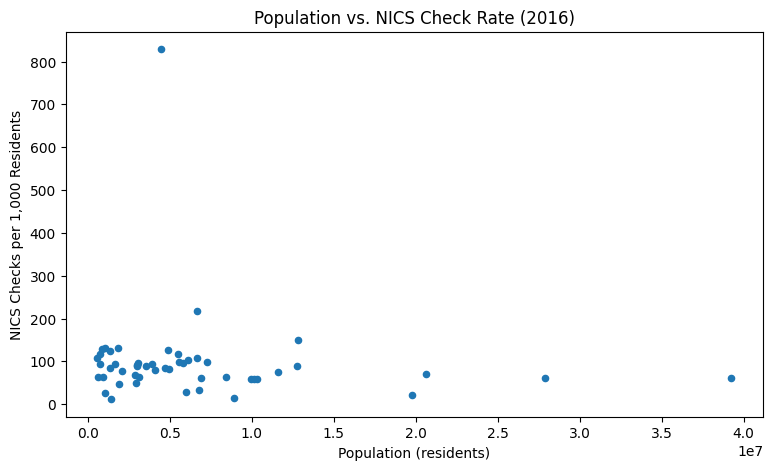

In [42]:
# Compare population with NICS check rates.
plot_relationship(
    final_df, "Population", "Checks_per_1000",
    "Population vs. NICS Check Rate (2016)", "Population (residents)"
)

In [43]:
without_kentucky = final_df[final_df.index != "Kentucky"]
without_kentucky.shape

(49, 5)

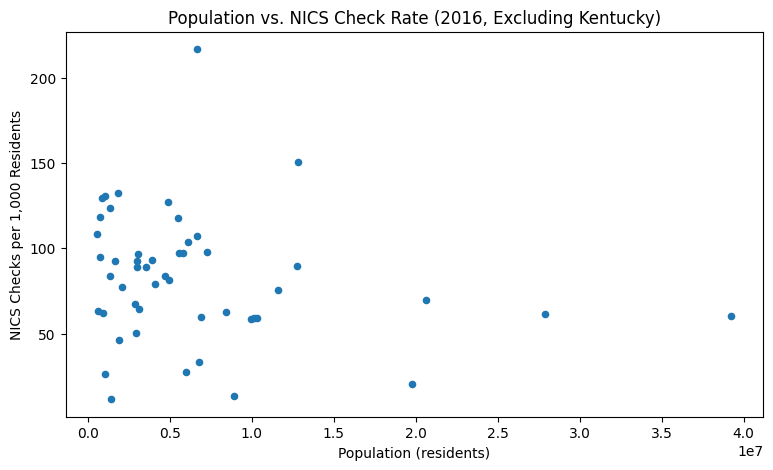

In [44]:
# Compare population with NICS check rates excluding Kentucky.
plot_relationship(
    without_kentucky, "Population", "Checks_per_1000",
    "Population vs. NICS Check Rate (2016, Excluding Kentucky)", "Population (residents)"
)


In [45]:
# Pearson correlations for the full 50-state sample and a sensitivity check.
corr_all = calculate_correlation(final_df, "Population")
corr_without_kentucky = calculate_correlation(without_kentucky, "Population")
print("All states:", round(corr_all, 3))
print("Without Kentucky:", round(corr_without_kentucky, 3))

All states: -0.103
Without Kentucky: -0.195


The analysis revealed a weak negative correlation between population size and NICS background check rates in 2016 (r = -0.103). After excluding Kentucky, an outlier with an unusually high check rate, the correlation became slightly more negative (r = -0.195). These findings suggest that states with larger populations do not necessarily have higher background check rates per capita.

### Research Question 3: Is median household income associated with NICS background check rates?

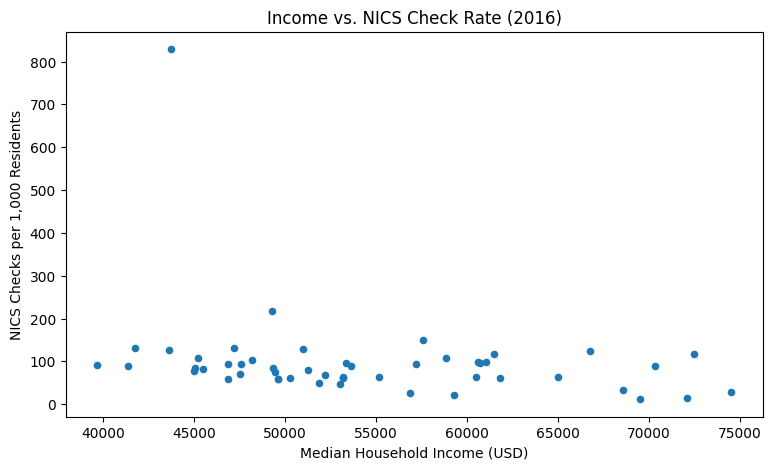

In [46]:
# Compare income with NICS check rates.
plot_relationship(
    final_df, "Income", "Checks_per_1000",
    "Income vs. NICS Check Rate (2016)", "Median Household Income (USD)"
)

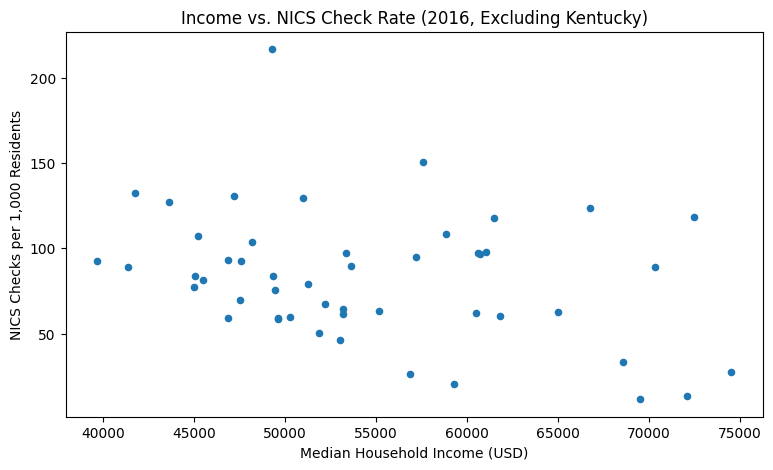

In [47]:
# Compare income with NICS check rates excluding Kentucky.
plot_relationship(
    without_kentucky, "Income", "Checks_per_1000",
    "Income vs. NICS Check Rate (2016, Excluding Kentucky)", "Median Household Income (USD)"
)


In [48]:
# Pearson correlations for the full 50-state sample and a sensitivity check.
corr_all = calculate_correlation(final_df, "Income")
corr_without_kentucky = calculate_correlation(without_kentucky, "Income")
print("All states:", round(corr_all, 3))
print("Without Kentucky:", round(corr_without_kentucky, 3))

All states: -0.264
Without Kentucky: -0.314


The analysis shows a weak negative correlation between median household income and NICS background check rates in 2016 (r = -0.264). After excluding Kentucky, the correlation became slightly stronger (r = -0.314). This suggests that higher-income states tend to have somewhat lower background check rates per capita. However, the relationship is not strong, and correlation does not imply causation.

### Research Question 4: How are poverty rates associated with NICS background check rates?

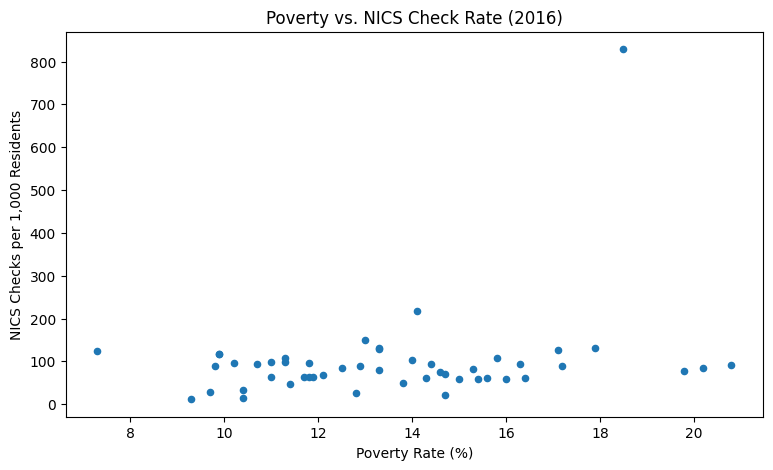

In [49]:
# Compare poverty with NICS check rates.
plot_relationship(
    final_df, "Poverty", "Checks_per_1000",
    "Poverty vs. NICS Check Rate (2016)", "Poverty Rate (%)"
)

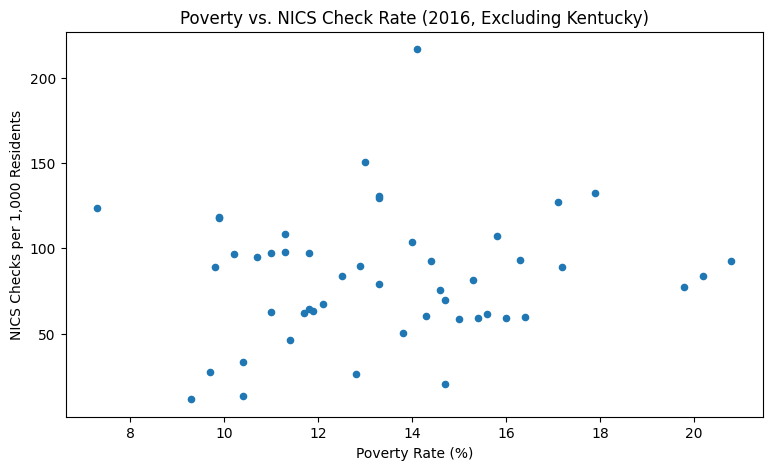

In [50]:
# Compare poverty with NICS check rates excluding Kentucky.
plot_relationship(
    without_kentucky, "Poverty", "Checks_per_1000",
    "Poverty vs. NICS Check Rate (2016, Excluding Kentucky)", "Poverty Rate (%)"
)

In [51]:
# Pearson correlations for the full 50-state sample and a sensitivity check.
corr_all = calculate_correlation(final_df, "Poverty")
corr_without_kentucky = calculate_correlation(without_kentucky, "Poverty")
print("All states:", round(corr_all, 3))
print("Without Kentucky:", round(corr_without_kentucky, 3))

All states: 0.26
Without Kentucky: 0.11


The analysis shows a weak positive correlation between poverty rates and NICS background checks per 1,000 residents across U.S. states in 2016 (r = 0.260). After excluding Kentucky, the correlation decreases to 0.110, suggesting that Kentucky influences the overall relationship. However, both correlations are weak, and the results do not establish a causal relationship between poverty and NICS background check rates.

# Conclusions
### Historical trend (1999–2016)
NICS background check transactions increased substantially overall, from 9,043,747 in 1999 to 27,425,512 in 2016. The annual total declined in 2000, 2002, and 2014, so the growth was not uninterrupted. These counts are background check transactions, not gun sales.

### Distribution of NICS background check rates (Univariate Analysis)
The univariate analysis showed substantial variation in NICS background check rates across U.S. states in 2016. Kentucky had an unusually high rate of approximately 829 checks per 1,000 residents, extending the right tail of the distribution. This supports examining Kentucky’s influence on the correlation results. The check rate measures transactions, not firearm purchases or individual gun ownership.

### Population and NICS background check rates
The correlation between population and checks per 1,000 residents was r = -0.103 for all 50 states and r = -0.195 without Kentucky. Both indicate weak negative linear associations; a larger state population does not necessarily correspond to a higher per-capita check rate.

### Median household income and NICS background check rates
The correlation was r = -0.264 for all states and r = -0.314 without Kentucky. This is a weak negative association, not evidence that higher income reduces background checks. The Census income measure covers 2011–2015, while NICS checks are from 2016.

### Poverty and NICS background check rates
After standardizing mixed percentage formats in the Census data, the correlation was r = 0.260 for all states and r = 0.110 without Kentucky. Both are weak positive associations. The change illustrates sensitivity to Kentucky's unusually high check rate.

## Limitations
- NICS totals count background check transactions, not firearm sales, ownership, or unique individuals. State reporting practices and permit-related checks may affect comparisons.
- The cross-sectional analysis uses 2016 NICS totals, a July 2016 population estimate, and Census socioeconomic measures that may cover different reference periods (income: 2011–2015).
- Kentucky is an influential observation. Excluding it is a sensitivity check, not a reason to delete it from the main dataset.
- Pearson correlations describe linear association only. No causal claims or statistical significance tests are made.
## Final summary
Population, income, and poverty each showed weak linear associations with NICS checks per 1,000 residents. These variables alone do not explain differences between states. Future research could investigate permit-check practices, state regulations, and multi-year patterns using consistently aligned measures.

In [52]:
!python -m nbconvert --to html Investigate_a_Dataset.ipynb

[NbConvertApp] Converting notebook Investigate_a_Dataset.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 8 image(s).
[NbConvertApp] Writing 735373 bytes to Investigate_a_Dataset.html
